# 🌳 Decision Tree

## 1. What is a Decision Tree?

A **Decision Tree** is a **supervised machine learning algorithm** used for:
- **Classification** problems (predicting categories)
- **Regression** problems (predicting continuous values)

It models decisions in the form of a **tree structure**, where:
- Each internal node represents a **feature test**
- Each branch represents a **decision rule**
- Each leaf node represents the **final output**

---

## 2. Structure of a Decision Tree

### 2.1 Root Node
- The topmost node
- Represents the **best feature** for splitting the data

### 2.2 Decision Nodes
- Intermediate nodes
- Perform tests like:
  - `Feature ≤ value`
  - `Feature == category`

### 2.3 Leaf Nodes
- Terminal nodes
- Contain:
  - Class label (classification)
  - Numerical value (regression)

### 2.4 Branches
- Outcomes of decision rules

---

## 3. Types of Decision Trees

### 3.1 Classification Tree
- Output is **categorical**
- Uses metrics like:
  - Gini Index
  - Entropy
  - Information Gain

### 3.2 Regression Tree
- Output is **continuous**
- Uses metrics like:
  - Mean Squared Error (MSE)
  - Mean Absolute Error (MAE)

---

## 4. How Does a Decision Tree Work?

1. Select the **best feature** to split the data
2. Split the dataset into subsets
3. Repeat recursively for each subset
4. Stop when:
   - All samples belong to one class
   - Maximum depth is reached
   - Minimum samples condition is met

---

## 5. Splitting Criteria

### 5.1 Gini Index (Classification)

Measures impurity in a node.

\[
Gini = 1 - \sum p_i^2
\]

- Lower Gini → purer node
- 0 → completely pure

---

### 5.2 Entropy (Classification)

Measures randomness.

\[
Entropy = - \sum p_i \log_2(p_i)
\]

---

### 5.3 Information Gain

Difference between parent and child entropy.

\[
IG = Entropy(parent) - Weighted\ Entropy(children)
\]

The feature with **maximum Information Gain** is chosen.

---

### 5.4 Mean Squared Error (Regression)

\[
MSE = \frac{1}{n} \sum (y - \hat{y})^2
\]

Lower MSE means better split.

---

## 6. Advantages of Decision Trees

- Easy to understand and interpret
- Requires little data preprocessing
- Handles nonlinear relationships
- Works with numerical and categorical data
- Can model complex decision rules

---

## 7. Disadvantages of Decision Trees

- Prone to **overfitting**
- Sensitive to small data changes
- Can become very large and complex
- Lower accuracy compared to ensemble models

---

## 8. Overfitting in Decision Trees

Occurs when the tree learns noise instead of patterns.

### Methods to Prevent Overfitting:
- Limit tree depth (`max_depth`)
- Set minimum samples per leaf (`min_samples_leaf`)
- Set minimum samples for split (`min_samples_split`)
- Pruning the tree

---

## 9. Decision Tree Algorithm (Pseudo Steps)

1. Start with the full dataset
2. Compute splitting metric for all features
3. Select best feature
4. Split the dataset
5. Repeat until stopping condition is met
6. Assign output at leaf nodes

---

## 10. Applications of Decision Trees

- Medical diagnosis
- Credit risk analysis
- Game logic (Tic-Tac-Toe, Chess)
- Customer churn prediction
- Fraud detection

---

## 11. Decision Tree in Python (Scikit-learn)

```python
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5
)

model.fit(X_train, y_train)


In [31]:
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt


In [32]:
df = pd.read_csv("tic-tac-toe.csv")
df.head()


,TL,TM,TR,ML,MM,MR,BL,BM,BR,class
0,x,x,x,x,o,o,x,o,o,True
1,x,x,x,x,o,o,o,x,o,True
2,x,x,x,x,o,o,o,o,x,True
3,x,x,x,x,o,o,o,b,b,True
4,x,x,x,x,o,o,b,o,b,True


In [33]:
X = df.drop("class", axis=1)
y = df["class"]

In [34]:
# Encode Categorical Features
encoder = LabelEncoder()

for col in X.columns:
    X[col] = encoder.fit_transform(X[col])


In [35]:
X.head()

,TL,TM,TR,ML,MM,MR,BL,BM,BR
0,2,2,2,2,1,1,2,1,1
1,2,2,2,2,1,1,1,2,1
2,2,2,2,2,1,1,1,1,2
3,2,2,2,2,1,1,1,0,0
4,2,2,2,2,1,1,0,1,0


In [36]:
y = y.astype(int)   # True → 1, False → 0

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [38]:
model = DecisionTreeClassifier(
    criterion="entropy",   # works well for categorical logic
    max_depth=6,           # prevent overfitting
    random_state=42
)

model.fit(X_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [39]:
y_pred = model.predict(X_test)
y_pred

array([1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0])

In [40]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.8125
              precision    recall  f1-score   support

           0       0.78      0.64      0.70        67
           1       0.82      0.90      0.86       125

    accuracy                           0.81       192
   macro avg       0.80      0.77      0.78       192
weighted avg       0.81      0.81      0.81       192



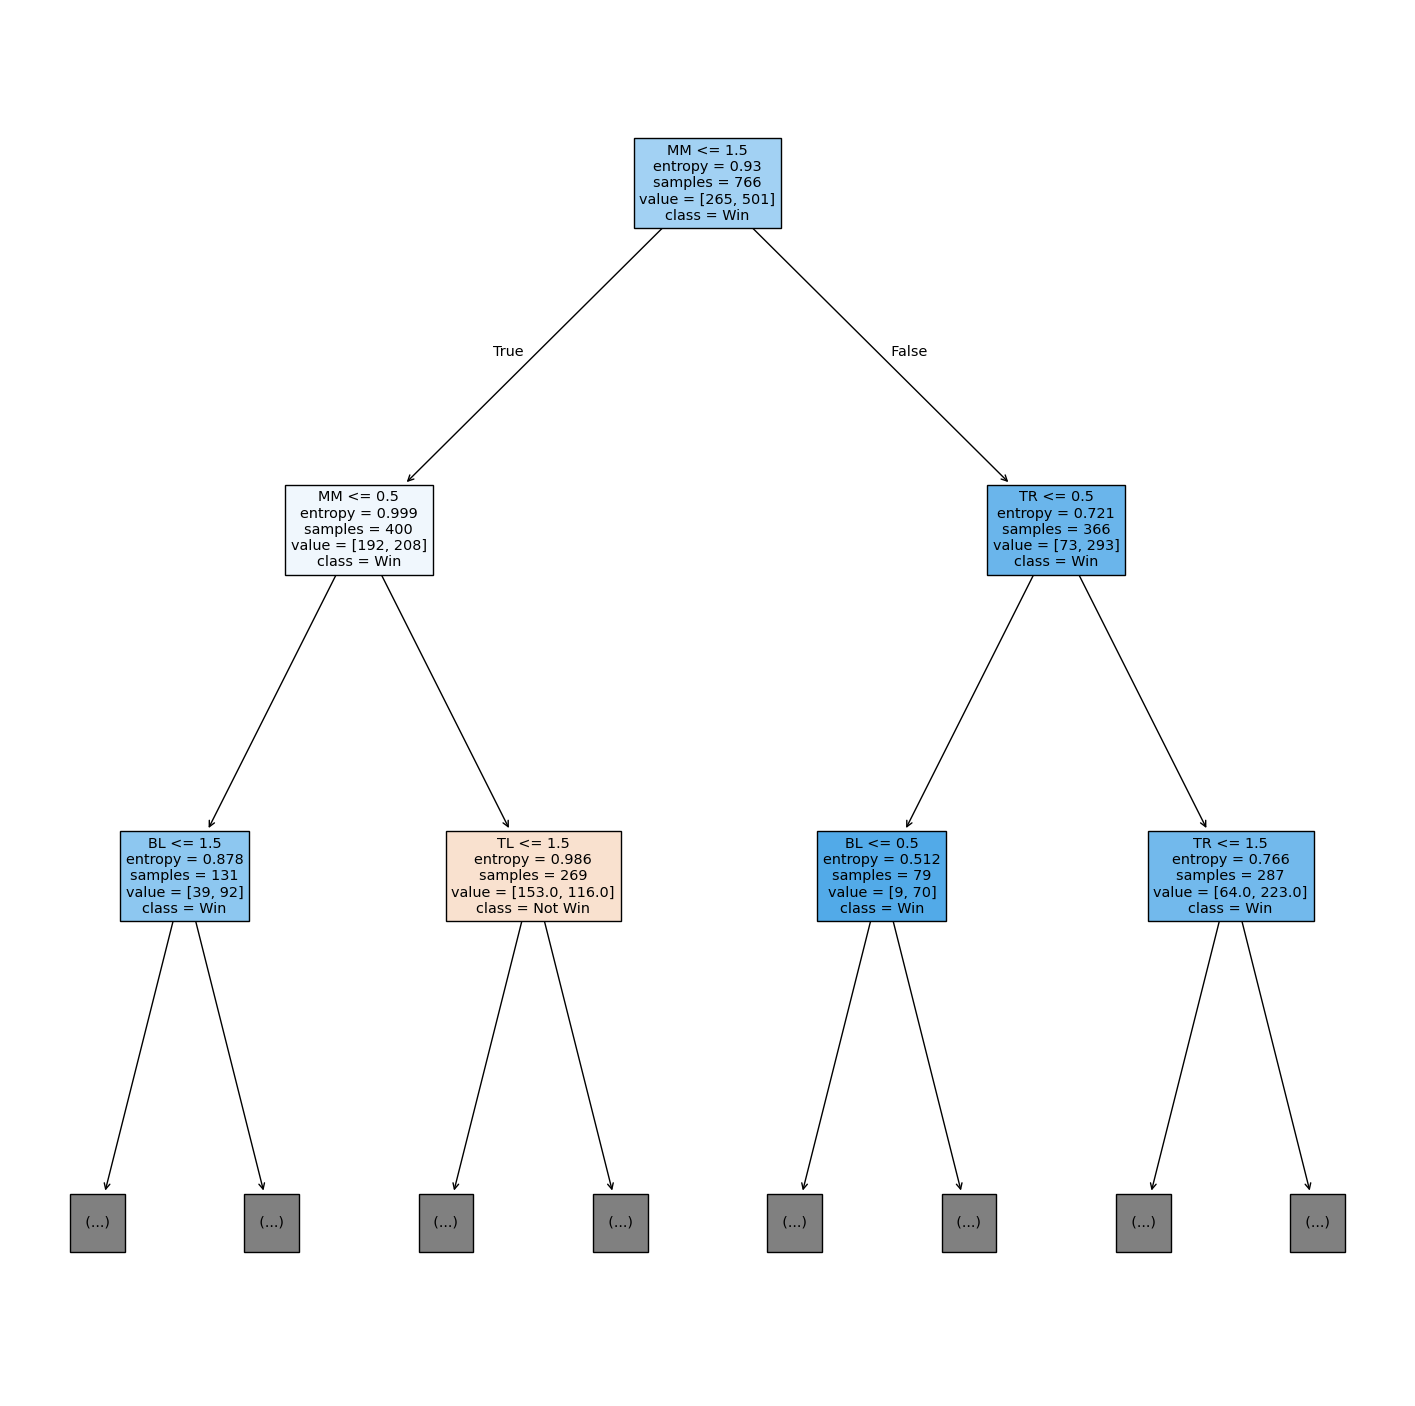

In [41]:
plt.figure(figsize=(18, 18))
plot_tree(
    model,
    feature_names=X.columns,
    max_depth=2,
    class_names=["Not Win", "Win"],
    filled=True
)
plt.show()
